# Déjà Code: finding competitive programming problems with the same idea

This notebook builds a semantic search and clustering system for CodeChef problems.
It runs top to bottom: clean the data, turn problem statements into numbers (TF-IDF and Sentence-BERT embeddings),
evaluate search two ways (topic tags and a hand-marked query set), cluster the problems, and analyse where the system fails.

Run **Kernel > Restart & Run All**. The first run takes about 10 minutes because it encodes 1,424 problems twice.
Embeddings are cached as `.npy` files next to the notebook; delete them to force a re-encode.

In [1]:
import os, re, ast, warnings
import numpy as np, pandas as pd
from collections import Counter
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics import normalized_mutual_info_score, silhouette_score
from sentence_transformers import SentenceTransformer
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

# Folder with questions.csv. If the notebook sits next to questions.csv, the current folder is used.
BASE = "." if os.path.exists("questions.csv") else r"C:\Users\HP\Downloads\archive"
raw_df = pd.read_csv(os.path.join(BASE, "questions.csv"))
print(raw_df.shape)
print(raw_df.columns.tolist())

(1474, 13)
['QCode', 'Title', 'link', 'level', 'statement', 'Author', 'Tester', 'Editorial', 'Tags', 'Date Added', 'Time Limit', 'Source Limit', 'Languages']


## 1. Explore the data
We only use `questions.csv` (the problem statements). `solutions.csv` is a log of submissions and the code files are about 1.2 GB,
and only about a quarter of the problems have an accepted solution, so they are not used.

In [2]:
print(raw_df.isna().sum())
print()
print("Duplicate titles:", raw_df["Title"].duplicated().sum())
print("Duplicate statements:", raw_df["statement"].duplicated().sum())
print()
print(raw_df["level"].value_counts())
print()
print(raw_df["statement"].str.len().describe())

QCode             0
Title             0
link              0
level             0
statement         0
Author            5
Tester          408
Editorial       248
Tags              0
Date Added        5
Time Limit        5
Source Limit      5
Languages         5
dtype: int64

Duplicate titles: 18
Duplicate statements: 44

level
medium       507
easy         478
hard         290
challenge    100
beginner      99
Name: count, dtype: int64

count     1474.000000
mean      2202.842605
std       1412.394153
min        128.000000
25%       1361.500000
50%       1893.500000
75%       2609.000000
max      16837.000000
Name: statement, dtype: float64


## 2. Clean the text
- remove the "All submissions for this problem are available" line that starts every statement
- cut off the sample input/output (numbers say nothing about the idea behind a problem)
- remove duplicate statements, so a problem cannot match its own copy
- drop statements under 200 characters (broken or trivial)
- keep only real topic tags (the raw tags are mostly author names and difficulty words) and merge duplicates like `dp` and `dynamic-prog`

In [3]:
df = raw_df.copy()


def clean_statement(text):
    text = text.replace("All submissions for this problem are available.", "")
    text = re.split(r"\n\s*Examples?\s*\n", text, maxsplit=1)[0]
    return re.sub(r"\s+", " ", text).strip()


def cut_samples(text):
    return re.split(r"(?:Sample Input|SAMPLE INPUT|Example Input)", text, maxsplit=1)[0].strip()


df["clean_text"] = df["statement"].apply(clean_statement)
n0 = len(df)
df = df.drop_duplicates(subset="clean_text").reset_index(drop=True)
print("Problems:", n0, "->", len(df), "after removing duplicates")

df["clean_text"] = df["clean_text"].apply(cut_samples)
df = df[df["clean_text"].str.len() >= 200].reset_index(drop=True)
print("Problems after dropping very short texts:", len(df))

df["tag_list"] = df["Tags"].apply(ast.literal_eval)
topic_map = {
    "dp": "dynamic-programming", "dynamic-prog": "dynamic-programming",
    "dynamic-programming": "dynamic-programming",
    "greedy": "greedy",
    "maths": "math", "math": "math", "simple-math": "math",
    "combinatorics": "combinatorics",
    "segment-tree": "segment-tree",
    "graph": "graph", "bfs": "graph", "dfs": "graph",
    "sorting": "sorting",
    "geometry": "geometry",
    "binary-search": "binary-search",
    "number-theory": "number-theory",
    "data-structure": "data-structures",
    "strings": "strings", "string": "strings",
    "bit": "bit-manipulation",
    "matrix-expo": "matrix-exponentiation",
    "probability": "probability",
    "implementation": "implementation",
    "ad-hoc": "ad-hoc",
}
df["topics"] = df["tag_list"].apply(
    lambda tags: sorted({topic_map[t.lower()] for t in tags if t.lower() in topic_map}))
print("Problems with at least one topic tag:", int((df["topics"].str.len() > 0).sum()), "of", len(df))
print(Counter(t for ts in df["topics"] for t in ts).most_common())

Problems: 1474 -> 1430 after removing duplicates
Problems after dropping very short texts: 1424
Problems with at least one topic tag: 620 of 1424
[('dynamic-programming', 139), ('math', 104), ('ad-hoc', 91), ('graph', 66), ('greedy', 64), ('segment-tree', 45), ('combinatorics', 45), ('sorting', 36), ('strings', 30), ('geometry', 29), ('implementation', 27), ('binary-search', 24), ('number-theory', 21), ('data-structures', 20), ('bit-manipulation', 19), ('matrix-exponentiation', 15), ('probability', 14)]


## 3. Second cleaning pass: remove story boilerplate
Clusters built on the first cleaning were held together by translation notices ("subtask", "Russian", "Vietnamese")
and recurring story characters (Chef, Sereja, Devu, Ciel). `clean_text2` removes those sentences and names.
Both versions are kept so the effect can be measured.

In [4]:
names = r"chef|chefs|chefland|sereja|devu|ciel|byteland|little elephant"


def clean2(t):
    sents = re.split(r"(?<=[.!?])\s+", t)
    sents = [s for s in sents if not re.search(
        r"mandarin|chinese|russian|vietnamese|bengali|translat|subtask", s, re.I)]
    t = " ".join(sents)
    t = re.sub(r"\b(" + names + r")\b", " ", t, flags=re.I)
    return re.sub(r"\s+", " ", t).strip()


df["clean_text2"] = df["clean_text"].apply(clean2)

# one scraped contest-page header ("Avantika") is not a problem at all; keep it out of search results
junk_pat = r"getServerOffset|document\)\.ready|var start_date|contest_name|GetCount"
junk_mask = df["clean_text"].str.contains(junk_pat, regex=True).values
print("Scraped-code statements blocked from search:", int(junk_mask.sum()), df.loc[junk_mask, "Title"].tolist())

raw_idx = raw_df.drop_duplicates(subset="Title", keep="first").set_index("Title")
kept = df["clean_text"].str.len() / df["Title"].map(lambda t: len(raw_idx.loc[t, "statement"]) if t in raw_idx.index else np.nan)
print("Median share of the raw statement kept after cleaning:", round(float(kept.median()), 2))

Scraped-code statements blocked from search: 1 ['Avantika']
Median share of the raw statement kept after cleaning: 0.82


## 4. Turn problems into numbers
- **TF-IDF** scores words by how distinctive they are, so it matches on wording.
- **Sentence-BERT embeddings** (`all-MiniLM-L6-v2`) turn a passage into a vector that captures meaning; closeness is measured with cosine similarity.
- **Centering** subtracts the average embedding from every problem. It reduces "hub" problems that show up in everyone's results.

Three embedding versions are compared: original text, cleaned text (`clean_text2`), cleaned + centered.

In [5]:
model = SentenceTransformer("all-MiniLM-L6-v2")
model.max_seq_length = 512


def load_or_encode(texts, fname):
    path = os.path.join(BASE, fname)
    if os.path.exists(path):
        m = np.load(path)
        if m.shape[0] == len(texts):
            print("loaded", fname)
            return m
    m = model.encode(texts, batch_size=32, show_progress_bar=True, normalize_embeddings=True)
    np.save(path, m)
    return m


emb = load_or_encode(df["clean_text"].tolist(), "embeddings.npy")
emb2 = load_or_encode(df["clean_text2"].tolist(), "embeddings_v2.npy")

mean_vec = emb2.mean(axis=0)
emb3 = emb2 - mean_vec
emb3 = emb3 / np.linalg.norm(emb3, axis=1, keepdims=True)

tfidf = TfidfVectorizer(stop_words="english", max_features=20000, ngram_range=(1, 2))
tfidf_matrix = tfidf.fit_transform(df["clean_text"])
tfidf2 = TfidfVectorizer(stop_words="english", max_features=20000, ngram_range=(1, 2))
tm2 = tfidf2.fit_transform(df["clean_text2"])
print(len(df), emb.shape, emb2.shape, emb3.shape)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

loaded embeddings.npy
loaded embeddings_v2.npy
1424 (1424, 384) (1424, 384) (1424, 384)


## 5. Evaluation A: topic tags (automatic)
Each tagged problem is used as a query; its own entry is excluded. A result counts as correct if it shares a topic tag with the query.
Vague tags (`math`, `ad-hoc`, `implementation`) are left out. This is a rough proxy: many problems have no tag, and sharing a tag is weak evidence of a shared idea.
We also measure how often a problem's nearest neighbours share its author (a sign the model matches author style) and "hubs"
(problems that appear in many other problems' top-5 lists).

In [6]:
sharp = {"dynamic-programming", "graph", "greedy", "segment-tree", "combinatorics", "sorting", "strings",
         "geometry", "binary-search", "number-theory", "data-structures", "bit-manipulation",
         "matrix-exponentiation", "probability"}
st = [set(ts) & sharp for ts in df["topics"]]
labeled = [i for i in range(len(df)) if st[i]]
print("Problems used for evaluation:", len(labeled))


def evaluate_tags(sim, k=5):
    sim = np.array(sim, dtype=float)
    np.fill_diagonal(sim, -np.inf)
    prec, rr = [], []
    for i in labeled:
        order = np.argsort(sim[i])[::-1][:50]
        rel = [bool(st[j] & st[i]) for j in order]
        prec.append(np.mean(rel[:k]))
        rr.append(1 / (rel.index(True) + 1) if True in rel else 0)
    return round(float(np.mean(prec)), 3), round(float(np.mean(rr)), 3)


auth = df["Author"].fillna("?").values


def neighbour_stats(sim, k=5):
    s = np.array(sim, dtype=float)
    np.fill_diagonal(s, -np.inf)
    top = np.argsort(s, axis=1)[:, ::-1][:, :k]
    c = np.bincount(top.ravel(), minlength=len(df))
    same_auth = np.mean([[auth[j] == auth[i] and auth[i] != "?" for j in top[i]] for i in range(len(df))])
    return round(float(same_auth), 3), int(c.max()), int((c == 0).sum()), c


sims = {
    "TF-IDF": (tfidf_matrix @ tfidf_matrix.T).toarray(),
    "Embeddings (original)": emb @ emb.T,
    "Embeddings (cleaned)": emb2 @ emb2.T,
    "Embeddings (cleaned + centered)": emb3 @ emb3.T,
}

chance = []
for i in labeled:
    shares = sum(1 for j in range(len(df)) if j != i and (st[j] & st[i]))
    chance.append(shares / (len(df) - 1))
print("Random baseline Precision@5:", round(float(np.mean(chance)), 3))

rows, hub_counts = {}, {}
for name, s in sims.items():
    p5, mrr = evaluate_tags(s)
    sa, mx, never, c = neighbour_stats(s)
    rows[name] = (p5, mrr, sa, mx, never)
    hub_counts[name] = c
tag_table = pd.DataFrame(rows, index=["Precision@5 (tags)", "MRR (tags)", "Top-5 neighbours with same author",
                                      "Max times one problem is in a top-5", "Problems never in any top-5"]).T
print(tag_table)

Problems used for evaluation: 474
Random baseline Precision@5: 0.054
                                 Precision@5 (tags)  MRR (tags)  \
TF-IDF                                        0.125       0.270   
Embeddings (original)                         0.154       0.316   
Embeddings (cleaned)                          0.123       0.258   
Embeddings (cleaned + centered)               0.132       0.268   

                                 Top-5 neighbours with same author  \
TF-IDF                                                       0.175   
Embeddings (original)                                        0.138   
Embeddings (cleaned)                                         0.097   
Embeddings (cleaned + centered)                              0.098   

                                 Max times one problem is in a top-5  \
TF-IDF                                                          44.0   
Embeddings (original)                                           42.0   
Embeddings (cleaned)        

## 6. Clustering
K-Means on the embeddings. The silhouette score is very low and nearly flat for every k (typical for text), so k=12 was chosen for readability, not because a score peaked.

In [7]:
for k in [8, 12, 16, 20, 25, 30]:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(emb)
    print(k, round(silhouette_score(emb, km.labels_), 4))

8 0.0321
12 0.031
16 0.022
20 0.0216
25 0.028
30 0.0216


In [8]:
K = 12
df["cluster_v1"] = KMeans(n_clusters=K, n_init=10, random_state=42).fit(emb).labels_
df["cluster"] = KMeans(n_clusters=K, n_init=10, random_state=42).fit(emb2).labels_
df["cluster_v3"] = KMeans(n_clusters=K, n_init=10, random_state=42).fit(emb3).labels_

terms2 = np.array(tfidf2.get_feature_names_out())
overall2 = np.asarray(tm2.mean(axis=0)).ravel()
cluster_names = {}
for c in range(K):
    idx = np.where(df["cluster"] == c)[0]
    cm = np.asarray(tm2[idx].mean(axis=0)).ravel()
    words = terms2[(cm - overall2).argsort()[::-1][:8]]
    cluster_names[c] = ", ".join(words[:3])
    tags = Counter(t for ts in df.loc[idx, "topics"] for t in ts).most_common(3)
    print(f"\nCluster {c} ({len(idx)} problems): {cluster_names[c]}")
    print("  distinctive words:", ", ".join(words))
    print("  common tags:", tags)
    print("  examples:", df.loc[idx, "Title"].head(4).tolist())

single = [i for i in range(len(df)) if len(st[i]) == 1]
y = [list(st[i])[0] for i in single]
nmi = {
    "Embeddings (original)": normalized_mutual_info_score(y, df["cluster_v1"].values[single]),
    "Embeddings (cleaned)": normalized_mutual_info_score(y, df["cluster"].values[single]),
    "Embeddings (cleaned + centered)": normalized_mutual_info_score(y, df["cluster_v3"].values[single]),
}
print("\nCluster agreement with tags (NMI, higher = better):", {k: round(v, 3) for k, v in nmi.items()})


Cluster 0 (98 problems): cell, cells, matrix
  distinctive words: cell, cells, matrix, grid, row, columns, rows, height
  common tags: [('dynamic-programming', 12), ('greedy', 6), ('implementation', 5)]
  examples: ['Little Elephant and Magic', 'Way Out', 'Block Drop', 'Head office building']

Cluster 1 (107 problems): time, minutes, server
  distinctive words: time, minutes, server, elephants, velocity, minute, hour, password
  common tags: [('ad-hoc', 10), ('math', 9), ('graph', 8)]
  examples: ['Chef and Girlfriend', 'Sereja and Data Structures', 'Password Cracking Challenge', 'Ciel and password cracking']

Cluster 2 (82 problems): points, polygon, triangle
  distinctive words: points, polygon, triangle, point, coordinates, sticks, sides, plane
  common tags: [('geometry', 20), ('math', 7), ('sorting', 5)]
  examples: ['The Best Box', 'Fit Squares in Triangle', 'Polygon & Circles', 'Congruent triangles']

Cluster 3 (103 problems): query, queries, array
  distinctive words: query, q

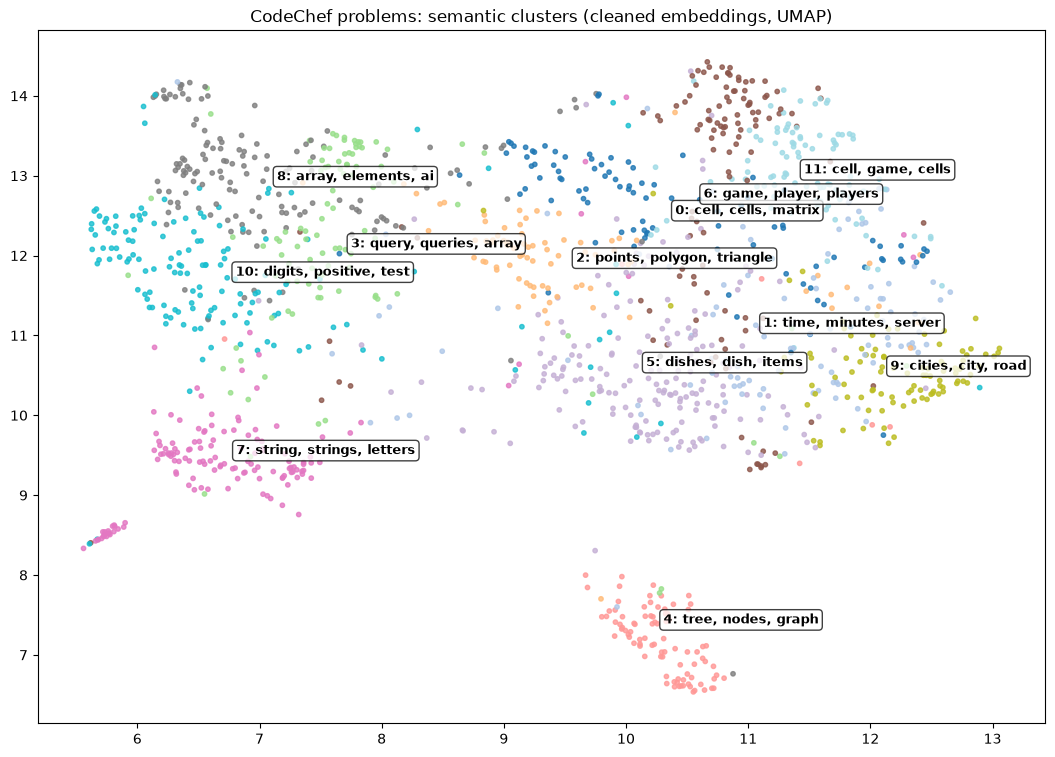

In [9]:
import umap

coords = umap.UMAP(n_neighbors=15, min_dist=0.1, metric="cosine", random_state=42).fit_transform(emb2)
plt.figure(figsize=(13, 9))
plt.scatter(coords[:, 0], coords[:, 1], c=df["cluster"], cmap="tab20", s=10, alpha=0.8)
for c in range(K):
    cx, cy = coords[df["cluster"] == c].mean(axis=0)
    plt.text(cx, cy, f"{c}: {cluster_names[c]}", fontsize=9, weight="bold",
             bbox=dict(facecolor="white", alpha=0.75, boxstyle="round"))
plt.title("CodeChef problems: semantic clusters (cleaned embeddings, UMAP)")
plt.savefig(os.path.join(BASE, "clusters_v2.png"), dpi=150, bbox_inches="tight")
plt.show()

## 7. Search
`find_similar` takes a pasted problem statement and returns the top matches.
Modes: `semantic` (centered embeddings), `tfidf` (keywords), `hybrid` (a 50/50 mix of both after min-max scaling).
The hybrid mix was not tuned; it is the default because the two signals fail in different places, not because it won a measured comparison.

In [10]:
def enc(text, clean=True):
    return model.encode([clean2(text) if clean else text], normalize_embeddings=True)[0]


def centered_q(text):
    q = enc(text) - mean_vec
    return q / np.linalg.norm(q)


def mask(s):
    return np.where(junk_mask, -np.inf, s)


def mm(x):
    return (x - x.min()) / (x.max() - x.min() + 1e-9)


def tfidf_top(text, k=5):
    return list(mask((tfidf_matrix @ tfidf.transform([text]).T).toarray().ravel()).argsort()[::-1][:k])


def top_orig(text, k=5):
    return list(mask(emb @ enc(text, clean=False)).argsort()[::-1][:k])


def top_clean(text, k=5):
    return list(mask(emb2 @ enc(text)).argsort()[::-1][:k])


def top_cent(text, k=5):
    return list(mask(emb3 @ centered_q(text)).argsort()[::-1][:k])


def top_hybrid(text, k=5, a=0.5):
    sem = emb3 @ centered_q(text)
    kw = (tfidf_matrix @ tfidf.transform([text]).T).toarray().ravel()
    return list(mask(a * mm(sem) + (1 - a) * mm(kw)).argsort()[::-1][:k])


def find_similar(problem_text, k=5, mode="hybrid", alpha=0.5):
    """mode: 'semantic' (meaning), 'tfidf' (keywords) or 'hybrid' (both)."""
    sem = emb3 @ centered_q(problem_text)
    kw = (tfidf_matrix @ tfidf.transform([problem_text]).T).toarray().ravel()
    if mode == "semantic":
        score = sem
    elif mode == "tfidf":
        score = kw
    else:
        score = alpha * mm(sem) + (1 - alpha) * mm(kw)
    score = np.where(junk_mask, -np.inf, score)
    top = score.argsort()[::-1][:k]
    out = df.iloc[top][["Title", "level", "topics"]].copy()
    out["cluster"] = [cluster_names[c] for c in df["cluster"].iloc[top]]
    out["score"] = score[top].round(3)
    return out


find_similar("Given a tree, find the diameter, the longest path between any two nodes.")

,Title,level,topics,cluster,score
253,Chef and Trees,easy,[],"tree, nodes, graph",0.910
854,Tree,medium,[bit-manipulation],"tree, nodes, graph",0.855
91,Trees Again,medium,[],"tree, nodes, graph",0.843
1363,Path containing K Nodes,medium,[graph],"tree, nodes, graph",0.788
1024,Prime Distance On Tree,hard,[graph],"tree, nodes, graph",0.772


## 8. Evaluation B: hand-marked query set
20 one-line queries written by me. For each, the top-5 results of the final system and of TF-IDF were read in full and marked relevant
only if they ask for the same task (or a harder variant of the same task) as the query; sharing a topic such as "graph" does not count.
Queries 12 and 17 were badly worded and are dropped; the 4 queries where nothing relevant was found count as zeros.

Limits: one annotator, only these two methods were pooled when marking (so the other rows are lower bounds), and with 18 queries the uncertainty is wide.

In [11]:
my_queries = [
    "Find the shortest path between two cities in a weighted road network",
    "Count the connected components of an undirected graph",
    "Find the longest path between any two nodes of a tree",
    "Count the number of ways to climb N stairs taking 1 or 2 steps at a time",
    "Find the longest increasing subsequence of an array",
    "Pick items with given weights and values to maximize total value within a weight limit",
    "Schedule the maximum number of non-overlapping activities given start and end times",
    "Buy the cheapest items first to get as many items as possible with a fixed budget",
    "Answer range sum queries on an array with point updates in between",
    "Two players take turns removing stones from piles, decide who wins with optimal play",
    "Count the ways to choose K items out of N, modulo a large prime",
    "Sort an array by a custom rule and output the K-th element",
    "Count the palindromic substrings of a string",
    "Check whether a pattern string occurs inside a larger string",
    "Compute the area of a polygon given the coordinates of its vertices",
    "Compute the expected value of the sum after rolling dice N times",
    "Find the smallest value that satisfies a condition using binary search on the answer",
    "Count the prime numbers up to N",
    "Find the pair of numbers in an array with the maximum XOR",
    "Compute the N-th Fibonacci number modulo 10^9+7 for a very large N",
]

key = {
    1: {"Two Closest", "Shortest path queries"},
    2: {"Chef and Graph Queries"},
    3: {"Tree"},
    4: {"Climbing Stairs"},
    5: {"An interesting subsequence"},
    6: {"Chef and Shop", "Knapsack Problem"},
    7: {"The Sports Stadium", "Event Organizer"},
    9: {"Addition and Multiplication", "Chef and Churu"},
    10: {"Dual Nim", "Ankit, Srijan and a game of stone piles", "Chef Game", "Exponential Game"},
    11: {"Chef team"},
    13: {"3-Palindromes"},
    14: {"Chef and The String of Digits"},
    18: {"Prime Generator"},
    19: {"And Operation", "Chef and Pie", "Polo the Penguin and the Tree"},
}
for q, titles in key.items():
    for t in titles:
        n = int((df["Title"] == t).sum())
        if n != 1:
            print("check title:", q, t, "matches", n)

methods = {
    "TF-IDF": tfidf_top,
    "Embeddings (original)": top_orig,
    "Embeddings (cleaned)": top_clean,
    "Embeddings (cleaned + centered)": top_cent,
    "Hybrid (centered + TF-IDF)": top_hybrid,
}
qs_all = [q for q in range(1, 21) if q not in (12, 17)]
per = {}
for name, fn in methods.items():
    per[name] = np.array([
        np.mean([df["Title"][j] in key.get(q, set()) for j in fn(my_queries[q - 1])])
        for q in qs_all])

rng = np.random.default_rng(0)
idx = rng.integers(0, len(qs_all), (2000, len(qs_all)))
rows = {}
for name, v in per.items():
    lo, hi = np.percentile(v[idx].mean(axis=1), [2.5, 97.5])
    dlo, dhi = np.percentile((v - per["TF-IDF"])[idx].mean(axis=1), [2.5, 97.5])
    rows[name] = (round(float(v.mean()), 3), f"{lo:.2f} to {hi:.2f}",
                  f"{dlo:+.2f} to {dhi:+.2f}", int((v > 0).sum()))
hand_table = pd.DataFrame(rows, index=["Precision@5 (hand-marked)", "95% range",
                                       "Diff vs TF-IDF (95%)", "Queries with a hit (of 18)"]).T
print(hand_table)

                                Precision@5 (hand-marked)     95% range  \
TF-IDF                                              0.111  0.04 to 0.20   
Embeddings (original)                               0.156  0.09 to 0.22   
Embeddings (cleaned)                                0.211  0.13 to 0.30   
Embeddings (cleaned + centered)                       0.2  0.11 to 0.29   
Hybrid (centered + TF-IDF)                          0.156  0.09 to 0.23   

                                Diff vs TF-IDF (95%)  \
TF-IDF                                +0.00 to +0.00   
Embeddings (original)                 -0.03 to +0.12   
Embeddings (cleaned)                  +0.02 to +0.19   
Embeddings (cleaned + centered)       +0.00 to +0.18   
Hybrid (centered + TF-IDF)            +0.01 to +0.09   

                                Queries with a hit (of 18)  
TF-IDF                                                   7  
Embeddings (original)                                   11  
Embeddings (cleaned)         

## 9. Failure analysis
Where the system goes wrong, with evidence.

In [12]:
# 9a. The same idea told as a different story, and an idea buried inside a long story
frog = """A frog stands on stone 1 of a river with N stones in a row. In one jump it can
move to the next stone or skip one stone. Count the number of different ways the frog
can reach stone N. Since the answer can be large, print it modulo 1000000007."""
for m in ["semantic", "tfidf", "hybrid"]:
    print("\n", m)
    print(find_similar(frog, mode=m)[["Title", "score"]])

hits = df.index[df["Title"] == "Climbing Stairs"]
if len(hits):
    i = hits[0]
    print("\nRank of 'Climbing Stairs' (a monk story hiding a 1-or-2-steps recurrence) for the stairs query:")
    for name, fn in methods.items():
        print(" ", name, "->", list(fn(my_queries[3], k=len(df))).index(i) + 1)


 semantic
                     Title  score
1172        Chef and Frogs  0.369
186          Chefs new Pet  0.358
206       Stepping Numbers  0.328
103         Dai Ma Chu Shi  0.283
933   Chef and Digit Jumps  0.275

 tfidf
                     Title  score
1083       Chef and Stones  0.251
789                  Ranka  0.208
287      Jewels and Stones  0.195
1178     Sereja and Stones  0.193
1188  Na2a and lucky stone  0.193

 hybrid
                     Title  score
1083       Chef and Stones  0.860
1188  Na2a and lucky stone  0.773
789                  Ranka  0.754
287      Jewels and Stones  0.747
1172        Chef and Frogs  0.713

Rank of 'Climbing Stairs' (a monk story hiding a 1-or-2-steps recurrence) for the stairs query:
  TF-IDF -> 1
  Embeddings (original) -> 225
  Embeddings (cleaned) -> 134
  Embeddings (cleaned + centered) -> 98
  Hybrid (centered + TF-IDF) -> 1


In [13]:
# 9b. Hubs: problems that appear in many other problems' top-5 lists
c = hub_counts["Embeddings (cleaned)"]
print("Hubs before centering:", [(df["Title"][i], int(c[i])) for i in c.argsort()[::-1][:6]])
c = hub_counts["Embeddings (cleaned + centered)"]
print("Hubs after centering: ", [(df["Title"][i], int(c[i])) for i in c.argsort()[::-1][:6]])

# 9c. Pairs the embeddings call close that share almost no words (different authors, a shared non-DP tag)
sim_e = emb2 @ emb2.T
sim_w = (tm2 @ tm2.T).toarray()
st2 = [s - {"dynamic-programming"} for s in st]
i_idx, j_idx = np.triu_indices(len(df), k=1)
e = sim_e[i_idx, j_idx]
w = sim_w[i_idx, j_idx]
ok = np.array([bool(st2[i] & st2[j]) and auth[i] != auth[j] and w[n] < 0.15
               for n, (i, j) in enumerate(zip(i_idx, j_idx))])
score = np.where(ok, e, -np.inf)
for n in np.argsort(score)[::-1][:10]:
    if not np.isfinite(score[n]):
        break
    i, j = i_idx[n], j_idx[n]
    print(f"\n{df['Title'][i]}  <->  {df['Title'][j]}")
    print(f"  embedding {e[n]:.2f} | word overlap {w[n]:.2f} | tags {st2[i] & st2[j]}")
    print("  A:", df["clean_text2"][i][:300])
    print("  B:", df["clean_text2"][j][:300])

Hubs before centering: [('Game of Divisors', 45), ('Game on a Grid', 42), ('Houses and Restaurants', 38), ('Chef and Walking on the rectangle', 38), ('Easy Queries', 35), ('The Amazing All-In-One Cooking Machine - Challenge', 30)]
Hubs after centering:  [('Game of Divisors', 26), ('Preparing Dishes', 24), ('Sereja and Array and Subtracting', 23), ('Two Roads', 22), ('Longest Weird Subsequence', 22), ('Festivals', 22)]

Roots of a Tree  <->  Tree Fun
  embedding 0.76 | word overlap 0.11 | tags {'graph'}
  A: You are given a tree with N nodes, numbered from 1 to N. You need to handle the queiries of the following two types: + x y. Add a path going from the node x to the node y (or from y to x because it's actually irrelevant). We will never add the path that is already a present one. - x y. Delete the pa
  B: David is a computer science student who loves his future profession. He is one of those who think that trees grow down, not up. David likes connected undirected acyclic graphs, also

## 10. Summary table for the README

In [15]:
summary = tag_table.copy()
summary["Cluster agreement with tags (NMI)"] = pd.Series({k: round(float(v), 3) for k, v in nmi.items()})
print(summary)
summary.to_csv(os.path.join(BASE, "results_tags.csv"))
hand_table.to_csv(os.path.join(BASE, "results_hand_marked.csv"))
df.drop(columns=["tag_list"]).to_csv(os.path.join(BASE, "clustered_questions_final.csv"), index=False)
print("saved results_tags.csv, results_hand_marked.csv, clustered_questions_final.csv")

                                 Precision@5 (tags)  MRR (tags)  \
TF-IDF                                        0.125       0.270   
Embeddings (original)                         0.154       0.316   
Embeddings (cleaned)                          0.123       0.258   
Embeddings (cleaned + centered)               0.132       0.268   

                                 Top-5 neighbours with same author  \
TF-IDF                                                       0.175   
Embeddings (original)                                        0.138   
Embeddings (cleaned)                                         0.097   
Embeddings (cleaned + centered)                              0.098   

                                 Max times one problem is in a top-5  \
TF-IDF                                                          44.0   
Embeddings (original)                                           42.0   
Embeddings (cleaned)                                            45.0   
Embeddings (cleaned + cen